In [29]:
%matplotlib inline

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import stft, resample_poly
from IPython.display import display, clear_output, Audio
from scipy.signal import butter, sosfiltfilt
import os
import json

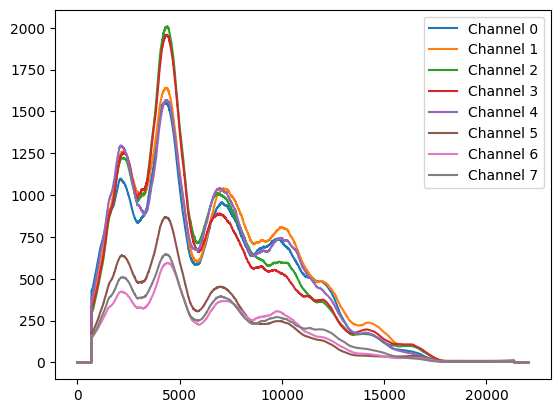

In [32]:
path = "../samples/default_array8_calibration.wav"

def moving_average(a, n=3):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    res = np.zeros(len(a))
    res[n//2:n//2+len(a)-n+1] = ret[n - 1:] / n
    return res

def rms_normalize(x):
    return x / (np.sqrt(np.mean(x * x)) + 1e-18)

x, sr = sf.read(path, always_2d=True)

n, m = x.shape
size = 2 * sr
samples = np.zeros((size, m))

f = 5000
marker = np.exp(np.arange(sr)*f/sr*2j*np.pi) / sr

N = 1
while N < x.shape[0]+sr:
    N *= 2

a = np.zeros(N, dtype=np.complex64)
b = np.zeros(N, dtype=np.complex64)

a[:x.shape[0]] = x[:,7]
b[:sr] = marker

y = np.abs(np.fft.ifft(np.fft.fft(a)*np.fft.fft(b)))
y = moving_average(y, sr)

peaks = []
ma = np.max(y)
for i in range(1, len(y)-1):
    if y[i] > y[i-1] and y[i] > y[i+1] and y[i] > 0.03 * ma and i+3*sr+size < n:
        if len(peaks) > 0 and i-peaks[-1] < sr:
            continue
        peaks.append(i)
        samples += rms_normalize(x[i+3*sr:i+size+3*sr])

# plt.plot(y)
# plt.scatter(peaks, y[peaks])

means = np.ones(m)
for i in range(m):
    X = np.fft.rfft(samples[:,i])
    f = np.fft.rfftfreq(size, 1/sr)
    plt.plot(f, moving_average(np.abs(X), size//32), label=f"Channel {i}")
    means[i] = np.sqrt(np.mean(samples[:,i] * samples[:,i]))

plt.legend()

calibration = np.max(means) / means
calibration = [*calibration]

calibf = os.path.splitext(os.path.basename(path))[0]+".json"
with open(calibf, "w", encoding="utf-8") as f:
    json.dump(calibration, f)


[0.00496161 0.0050064  0.00530885 0.00496141 0.00568599 0.00637902
 0.00547834 0.00437383]


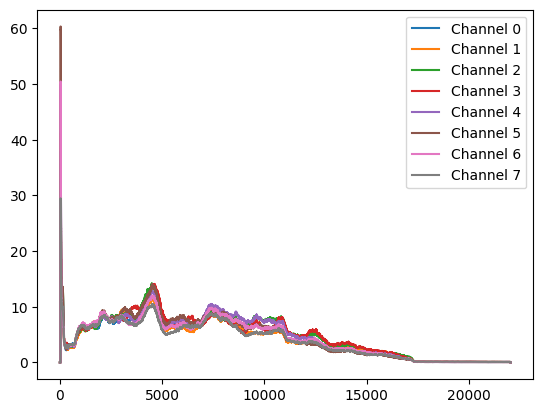

In [31]:
path = "../samples/testwalk.wav"

x, sr = sf.read(path, always_2d=True)
n, m = x.shape

x *= calibration

means = np.ones(m)
for i in range(m):
    X = np.fft.rfft(x[:,i])
    f = np.fft.rfftfreq(n, 1/sr)
    plt.plot(f, moving_average(np.abs(X), size//32), label=f"Channel {i}")
    means[i] = np.sqrt(np.mean(x[:,i] * x[:,i]))

print(means)

plt.legend()